In [18]:
print("FluAssist dataset analysis started")

FluAssist dataset analysis started


In [19]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 3.0.6


In [20]:
import pandas as pd

df = pd.read_csv("../datasets/unified_febrile_disease_dataset.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (2203, 16)


In [4]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Columns:
['Fever', 'Headache', 'Nausea', 'Muscle_Pain_Myalgia', 'Vomiting', 'Diarrhea', 'Joint_Pain', 'Arthritis', 'Joint_Swelling', 'Rash', 'Chills', 'Sweating', 'Fatigue', 'Eye_Orbital_Pain', 'Conjunctivitis', 'Disease']

First 5 rows:


,Fever,Headache,Nausea,Muscle_Pain_Myalgia,Vomiting,Diarrhea,Joint_Pain,Arthritis,Joint_Swelling,Rash,Chills,Sweating,Fatigue,Eye_Orbital_Pain,Conjunctivitis,Disease
0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,Typhoid
1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,Typhoid
2,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,Typhoid
3,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,Typhoid
4,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,Typhoid



Data types:
Fever                  int64
Headache               int64
Nausea                 int64
Muscle_Pain_Myalgia    int64
Vomiting               int64
Diarrhea               int64
Joint_Pain             int64
Arthritis              int64
Joint_Swelling         int64
Rash                   int64
Chills                 int64
Sweating               int64
Fatigue                int64
Eye_Orbital_Pain       int64
Conjunctivitis         int64
Disease                  str
dtype: object

Missing values:
Fever                  0
Headache               0
Nausea                 0
Muscle_Pain_Myalgia    0
Vomiting               0
Diarrhea               0
Joint_Pain             0
Arthritis              0
Joint_Swelling         0
Rash                   0
Chills                 0
Sweating               0
Fatigue                0
Eye_Orbital_Pain       0
Conjunctivitis         0
Disease                0
dtype: int64

Duplicate rows:
1132


In [5]:
print(df["Disease"].value_counts())

Disease
Chikungunya    1001
Dengue          618
Typhoid         500
Malaria          84
Name: count, dtype: int64


In [6]:
feature_columns = [col for col in df.columns if col != "Disease"]

for col in feature_columns:
    print(f"\n{col}:")
    print(df[col].unique())


Fever:
[1 0]

Headache:
[1 0]

Nausea:
[1 0]

Muscle_Pain_Myalgia:
[1 0]

Vomiting:
[0 1]

Diarrhea:
[0 1]

Joint_Pain:
[0 1]

Arthritis:
[0 1]

Joint_Swelling:
[0 1]

Rash:
[0 1]

Chills:
[0 1]

Sweating:
[0 1]

Fatigue:
[0 1]

Eye_Orbital_Pain:
[0 1]

Conjunctivitis:
[0 1]


In [7]:
print("Total rows:", len(df))
print("Unique rows:", len(df.drop_duplicates()))
print("Duplicate rows:", df.duplicated().sum())

Total rows: 2203
Unique rows: 1071
Duplicate rows: 1132


In [8]:
print(df[df.duplicated(keep=False)].head(20))

    Fever  Headache  Nausea  Muscle_Pain_Myalgia  Vomiting  Diarrhea  \
0       1         1       1                    1         0         0   
1       1         0       1                    0         0         0   
2       1         1       1                    0         0         1   
3       1         0       1                    1         0         1   
4       1         1       0                    0         0         1   
5       1         0       1                    1         0         1   
6       1         1       0                    1         0         1   
7       1         1       1                    1         0         1   
8       1         1       0                    1         0         1   
9       1         1       1                    1         0         1   
10      1         1       0                    1         0         1   
11      1         1       0                    0         0         1   
12      1         1       1                    0         0      

In [9]:
print(df["Disease"].unique())

<ArrowStringArray>
['Typhoid', 'Chikungunya', 'Malaria', 'Dengue']
Length: 4, dtype: str


In [10]:
# Check whether identical symptom patterns have different disease labels

feature_columns = [col for col in df.columns if col != "Disease"]

pattern_check = (
    df.groupby(feature_columns)["Disease"]
      .nunique()
      .reset_index(name="number_of_diseases")
)

print("Unique symptom patterns:", len(pattern_check))

print("\nPatterns associated with more than one disease:")
print(
    pattern_check[
        pattern_check["number_of_diseases"] > 1
    ]
)

Unique symptom patterns: 1055

Patterns associated with more than one disease:
     Fever  Headache  Nausea  Muscle_Pain_Myalgia  Vomiting  Diarrhea  \
373      1         0       0                    0         0         0   
399      1         0       0                    0         0         1   
428      1         0       0                    1         0         0   
457      1         0       0                    1         0         1   
496      1         0       1                    0         0         0   
524      1         0       1                    0         0         1   
567      1         0       1                    1         0         0   
608      1         0       1                    1         0         1   
665      1         1       0                    0         0         0   
687      1         1       0                    0         0         1   
729      1         1       0                    1         0         0   
768      1         1       0                 

In [11]:
# Show the actual disease combinations for ambiguous symptom patterns

ambiguous_patterns = (
    df.groupby(feature_columns)["Disease"]
      .agg(lambda x: sorted(x.unique()))
      .reset_index(name="diseases")
)

ambiguous_patterns = ambiguous_patterns[
    ambiguous_patterns["diseases"].apply(len) > 1
]

print("Number of ambiguous symptom patterns:",
      len(ambiguous_patterns))

display(ambiguous_patterns.head(20))

Number of ambiguous symptom patterns: 16


,Fever,Headache,Nausea,Muscle_Pain_Myalgia,Vomiting,Diarrhea,Joint_Pain,Arthritis,Joint_Swelling,Rash,Chills,Sweating,Fatigue,Eye_Orbital_Pain,Conjunctivitis,diseases
373,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
399,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
428,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
457,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
496,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
524,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
567,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
608,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
665,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"
687,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,"[Dengue, Typhoid]"


Matplotlib is building the font cache; this may take a moment.


Disease
Chikungunya    1001
Dengue          618
Typhoid         500
Malaria          84
Name: count, dtype: int64


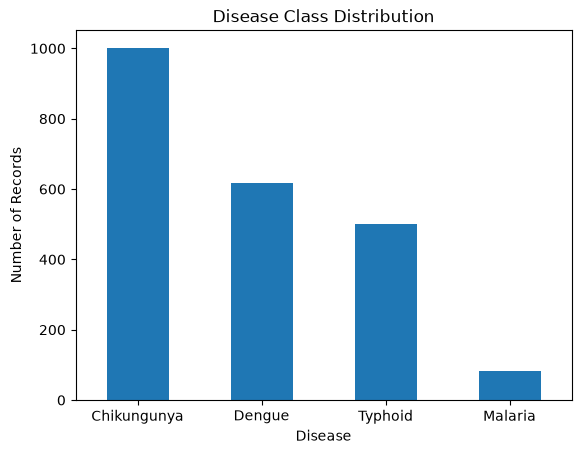

In [12]:
import matplotlib.pyplot as plt

counts = df["Disease"].value_counts()

print(counts)

counts.plot(kind="bar")
plt.title("Disease Class Distribution")
plt.xlabel("Disease")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [13]:
# Detailed analysis of ambiguous symptom patterns

feature_columns = [col for col in df.columns if col != "Disease"]

ambiguous_details = (
    df.groupby(feature_columns)["Disease"]
      .agg(
          diseases=lambda x: sorted(x.unique()),
          record_count="size"
      )
      .reset_index()
)

ambiguous_details = ambiguous_details[
    ambiguous_details["diseases"].apply(len) > 1
]

print("Number of ambiguous symptom patterns:",
      len(ambiguous_details))

display(
    ambiguous_details[
        ["diseases", "record_count"]
    ]
)

Number of ambiguous symptom patterns: 16


,diseases,record_count
373,"[Dengue, Typhoid]",28
399,"[Dengue, Typhoid]",14
428,"[Dengue, Typhoid]",38
457,"[Dengue, Typhoid]",22
496,"[Dengue, Typhoid]",16
524,"[Dengue, Typhoid]",33
567,"[Dengue, Typhoid]",32
608,"[Dengue, Typhoid]",57
665,"[Dengue, Typhoid]",31
687,"[Dengue, Typhoid]",40


In [14]:
# Check exact duplicate rows within each disease

duplicate_by_disease = (
    df.groupby("Disease")
      .apply(lambda x: x.duplicated().sum())
)

print(duplicate_by_disease)

Disease
Chikungunya     85
Dengue         512
Malaria         51
Typhoid        484
dtype: int64


In [15]:
# Remove exact duplicate rows temporarily for analysis
df_unique = df.drop_duplicates().copy()

print("Original records:", len(df))
print("After removing exact duplicates:", len(df_unique))
print("\nDisease distribution after deduplication:")
print(df_unique["Disease"].value_counts())

Original records: 2203
After removing exact duplicates: 1071

Disease distribution after deduplication:
Disease
Chikungunya    916
Dengue         106
Malaria         33
Typhoid         16
Name: count, dtype: int64


In [16]:
# Count how many unique records belong to ambiguous patterns

feature_columns = [col for col in df_unique.columns if col != "Disease"]

ambiguous_unique = (
    df_unique.groupby(feature_columns)["Disease"]
    .nunique()
)

ambiguous_unique = ambiguous_unique[
    ambiguous_unique > 1
]

print("Ambiguous unique symptom patterns:",
      len(ambiguous_unique))

Ambiguous unique symptom patterns: 16


In [17]:
# How many UNIQUE records are involved in Dengue/Typhoid ambiguity?

ambiguous_records = (
    df_unique.groupby(feature_columns)
    .filter(lambda x: x["Disease"].nunique() > 1)
)

print("Unique records involved in ambiguity:",
      len(ambiguous_records))

print("\nDisease counts among ambiguous records:")
print(ambiguous_records["Disease"].value_counts())

Unique records involved in ambiguity: 32

Disease counts among ambiguous records:
Disease
Typhoid    16
Dengue     16
Name: count, dtype: int64
